In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTENC
from sklearn.model_selection import GridSearchCV
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    RocCurveDisplay
)

import pickle

1. Load the dataset

In [4]:
df = pd.read_csv('/content/bank-full-nulls.csv', sep=';')
df

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58.0,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44.0,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33.0,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47.0,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33.0,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51.0,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71.0,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72.0,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57.0,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no


In [5]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58.0,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44.0,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33.0,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47.0,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33.0,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        44742 non-null  float64
 1   job        44730 non-null  object 
 2   marital    45211 non-null  object 
 3   education  45211 non-null  object 
 4   default    45211 non-null  object 
 5   balance    45211 non-null  int64  
 6   housing    45211 non-null  object 
 7   loan       45211 non-null  object 
 8   contact    45211 non-null  object 
 9   day        45211 non-null  int64  
 10  month      45211 non-null  object 
 11  duration   45211 non-null  int64  
 12  campaign   45211 non-null  int64  
 13  pdays      45211 non-null  int64  
 14  previous   45211 non-null  int64  
 15  poutcome   45211 non-null  object 
 16  y          45211 non-null  object 
dtypes: float64(1), int64(6), object(10)
memory usage: 5.9+ MB


In [7]:
df.shape

(45211, 17)

In [8]:
df['y'].value_counts()

,count
y,
no,39922
yes,5289


In [9]:
df['y'].value_counts(normalize=True) * 100

,proportion
y,
no,88.30152
yes,11.69848


In [10]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,44742.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.937531,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.615166,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [11]:
df.describe(include='object')

,job,marital,education,default,housing,loan,contact,month,poutcome,y
count,44730,45211,45211,45211,45211,45211,45211,45211,45211,45211
unique,12,3,4,2,2,2,3,12,4,2
top,blue-collar,married,secondary,no,yes,no,cellular,may,unknown,no
freq,9641,27214,23202,44396,25130,37967,29285,13766,36959,39922


In [12]:
print('Duplicate rows:',df.duplicated().sum())

Duplicate rows: 0


In [13]:
df.isnull().sum()

,0
age,469
job,481
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


In [14]:
for col in df.columns:
    print(col, ":", df[col].nunique())

age : 77
job : 12
marital : 3
education : 4
default : 2
balance : 7168
housing : 2
loan : 2
contact : 3
day : 31
month : 12
duration : 1573
campaign : 48
pdays : 559
previous : 41
poutcome : 4
y : 2


In [15]:
for col in df.select_dtypes(include='object').columns:
  print('\n', col)
  print('-'*20)
  print(df[col].value_counts())


 job
--------------------
job
blue-collar      9641
management       9346
technician       7515
admin.           5120
services         4110
retired          2244
self-employed    1559
entrepreneur     1466
unemployed       1283
housemaid        1224
student           935
unknown           287
Name: count, dtype: int64

 marital
--------------------
marital
married     27214
single      12790
divorced     5207
Name: count, dtype: int64

 education
--------------------
education
secondary    23202
tertiary     13301
primary       6851
unknown       1857
Name: count, dtype: int64

 default
--------------------
default
no     44396
yes      815
Name: count, dtype: int64

 housing
--------------------
housing
yes    25130
no     20081
Name: count, dtype: int64

 loan
--------------------
loan
no     37967
yes     7244
Name: count, dtype: int64

 contact
--------------------
contact
cellular     29285
unknown      13020
telephone     2906
Name: count, dtype: int64

 month
------------------

In [16]:
df['job'] = df['job'].str.strip().str.rstrip('.')

In [17]:
print(df["y"].value_counts(),'\n')
print(df["y"].value_counts(normalize=True) * 100)

y
no     39922
yes     5289
Name: count, dtype: int64 

y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


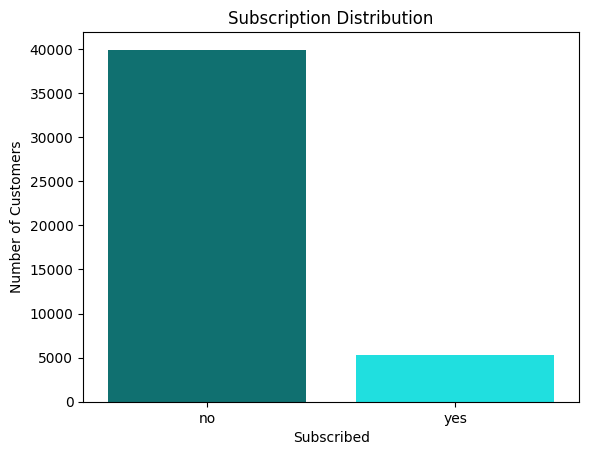

In [18]:
sns.countplot(data=df, x="y", hue='y',palette=["teal", "aqua"], legend=False)
plt.title("Subscription Distribution")
plt.xlabel("Subscribed")
plt.ylabel("Number of Customers")
plt.show()

In [19]:
numerical_features = df.select_dtypes(include=np.number).columns
print(numerical_features)

Index(['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous'], dtype='object')


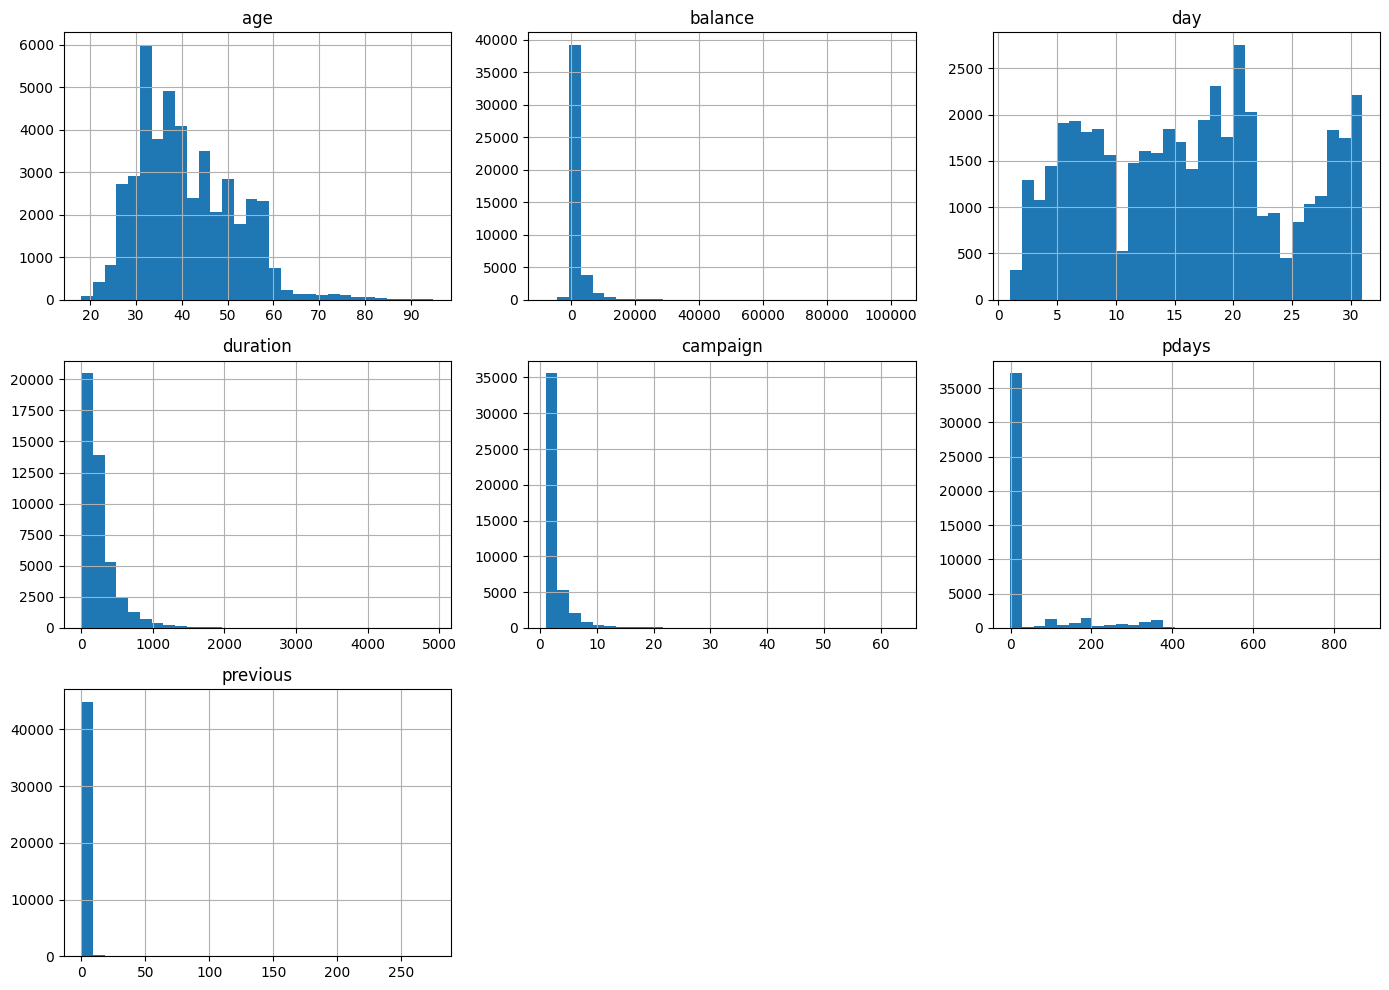

In [20]:
df[numerical_features].hist(
    figsize=(14, 10), bins=30
)
plt.tight_layout()
plt.show()

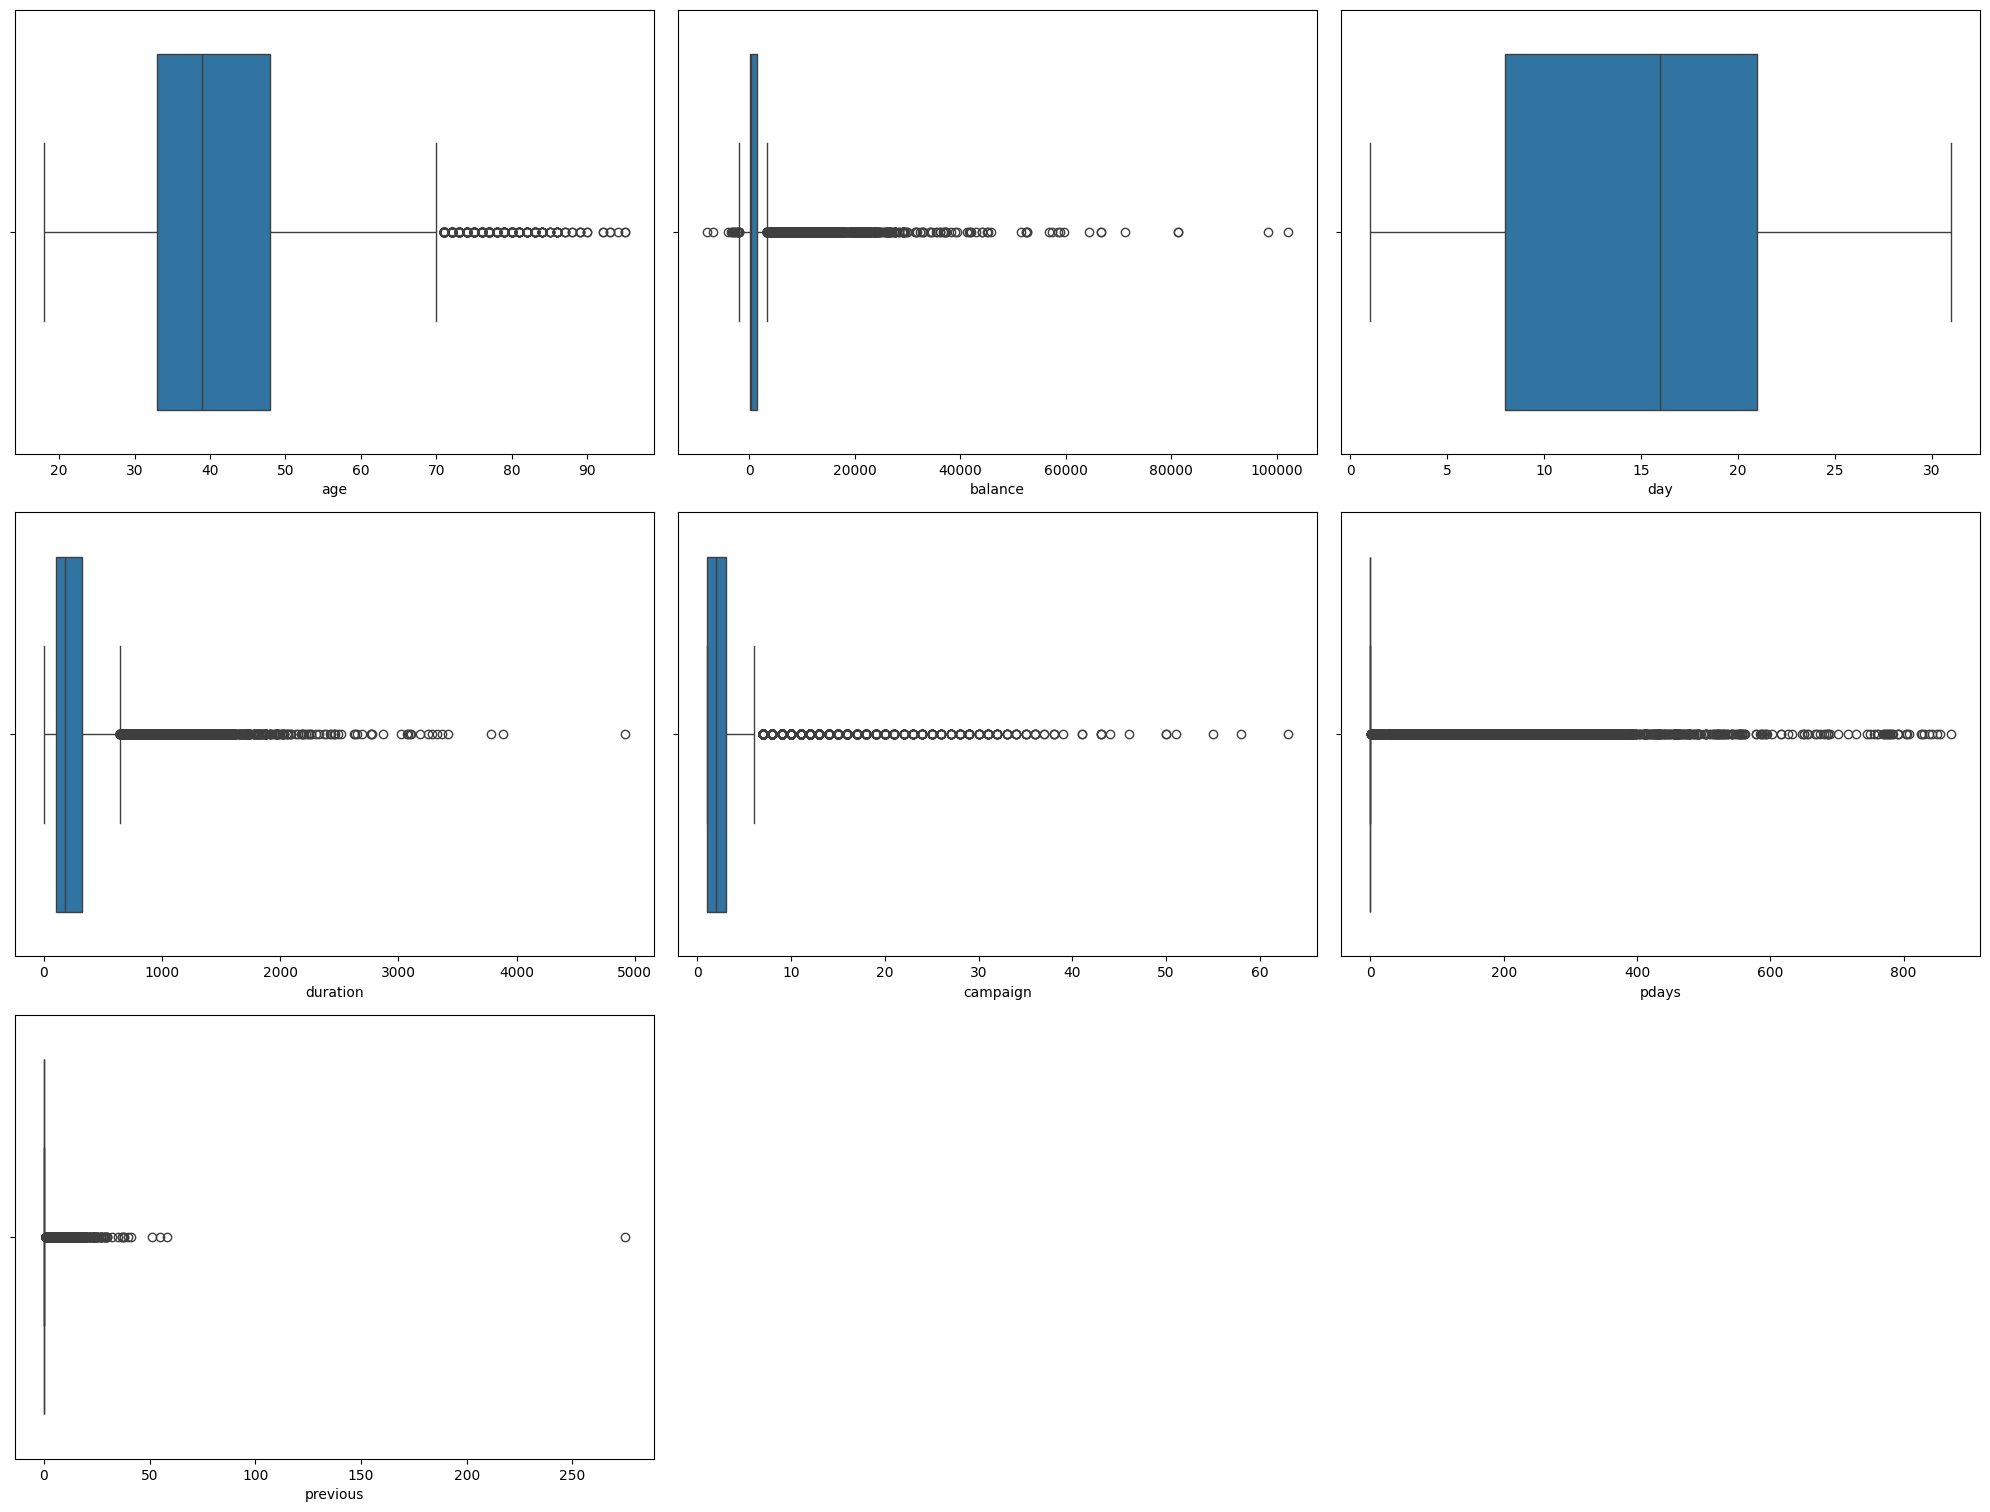

In [21]:
plt.figure(figsize=(20, 60), facecolor='white')

plotnumber = 1

for numerical_feature in numerical_features:
    ax = plt.subplot(12, 3, plotnumber)
    sns.boxplot(x=df[numerical_feature], ax=ax)
    plt.xlabel(numerical_feature)
    plotnumber += 1

plt.tight_layout()
plt.show()

In [22]:
categorical_features = df.select_dtypes(include="object").columns.drop("y")
print(categorical_features)

Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome'],
      dtype='object')


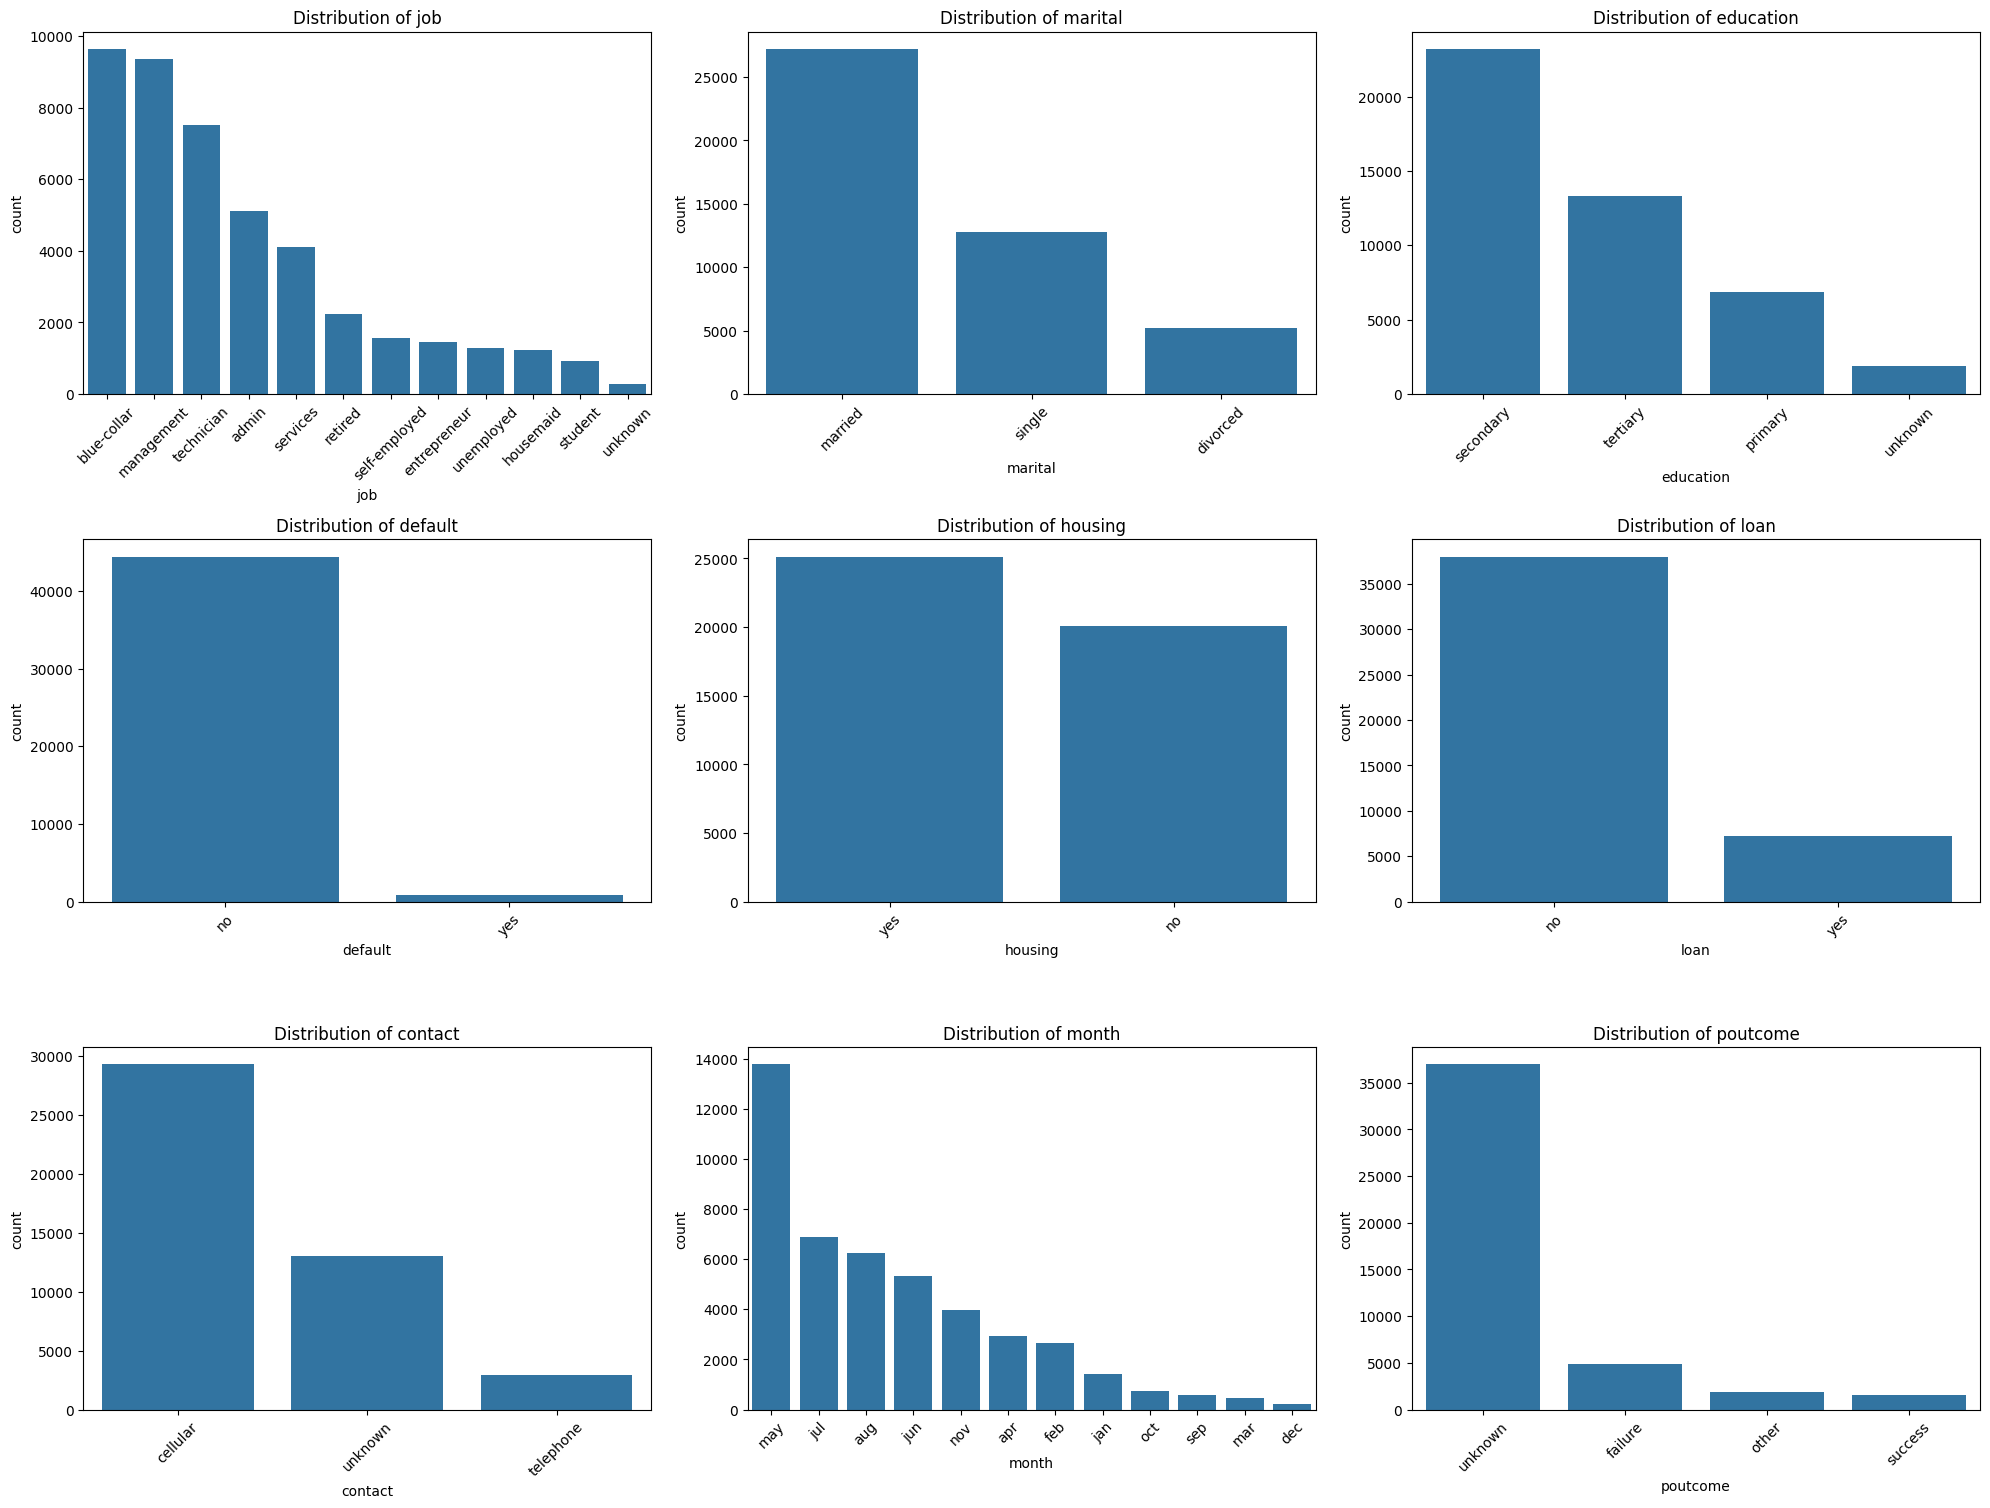

In [23]:
plt.figure(figsize=(20, 60), facecolor='white')

plotnumber = 1

for categorical_feature in categorical_features:
    ax = plt.subplot(12, 3, plotnumber)
    sns.countplot(data=df, x=categorical_feature, order=df[categorical_feature].value_counts().index)
    plt.title(f"Distribution of {categorical_feature}")
    plt.xticks(rotation=45)
    plotnumber += 1

plt.tight_layout()
plt.show()

Analyze subscription against categorical features

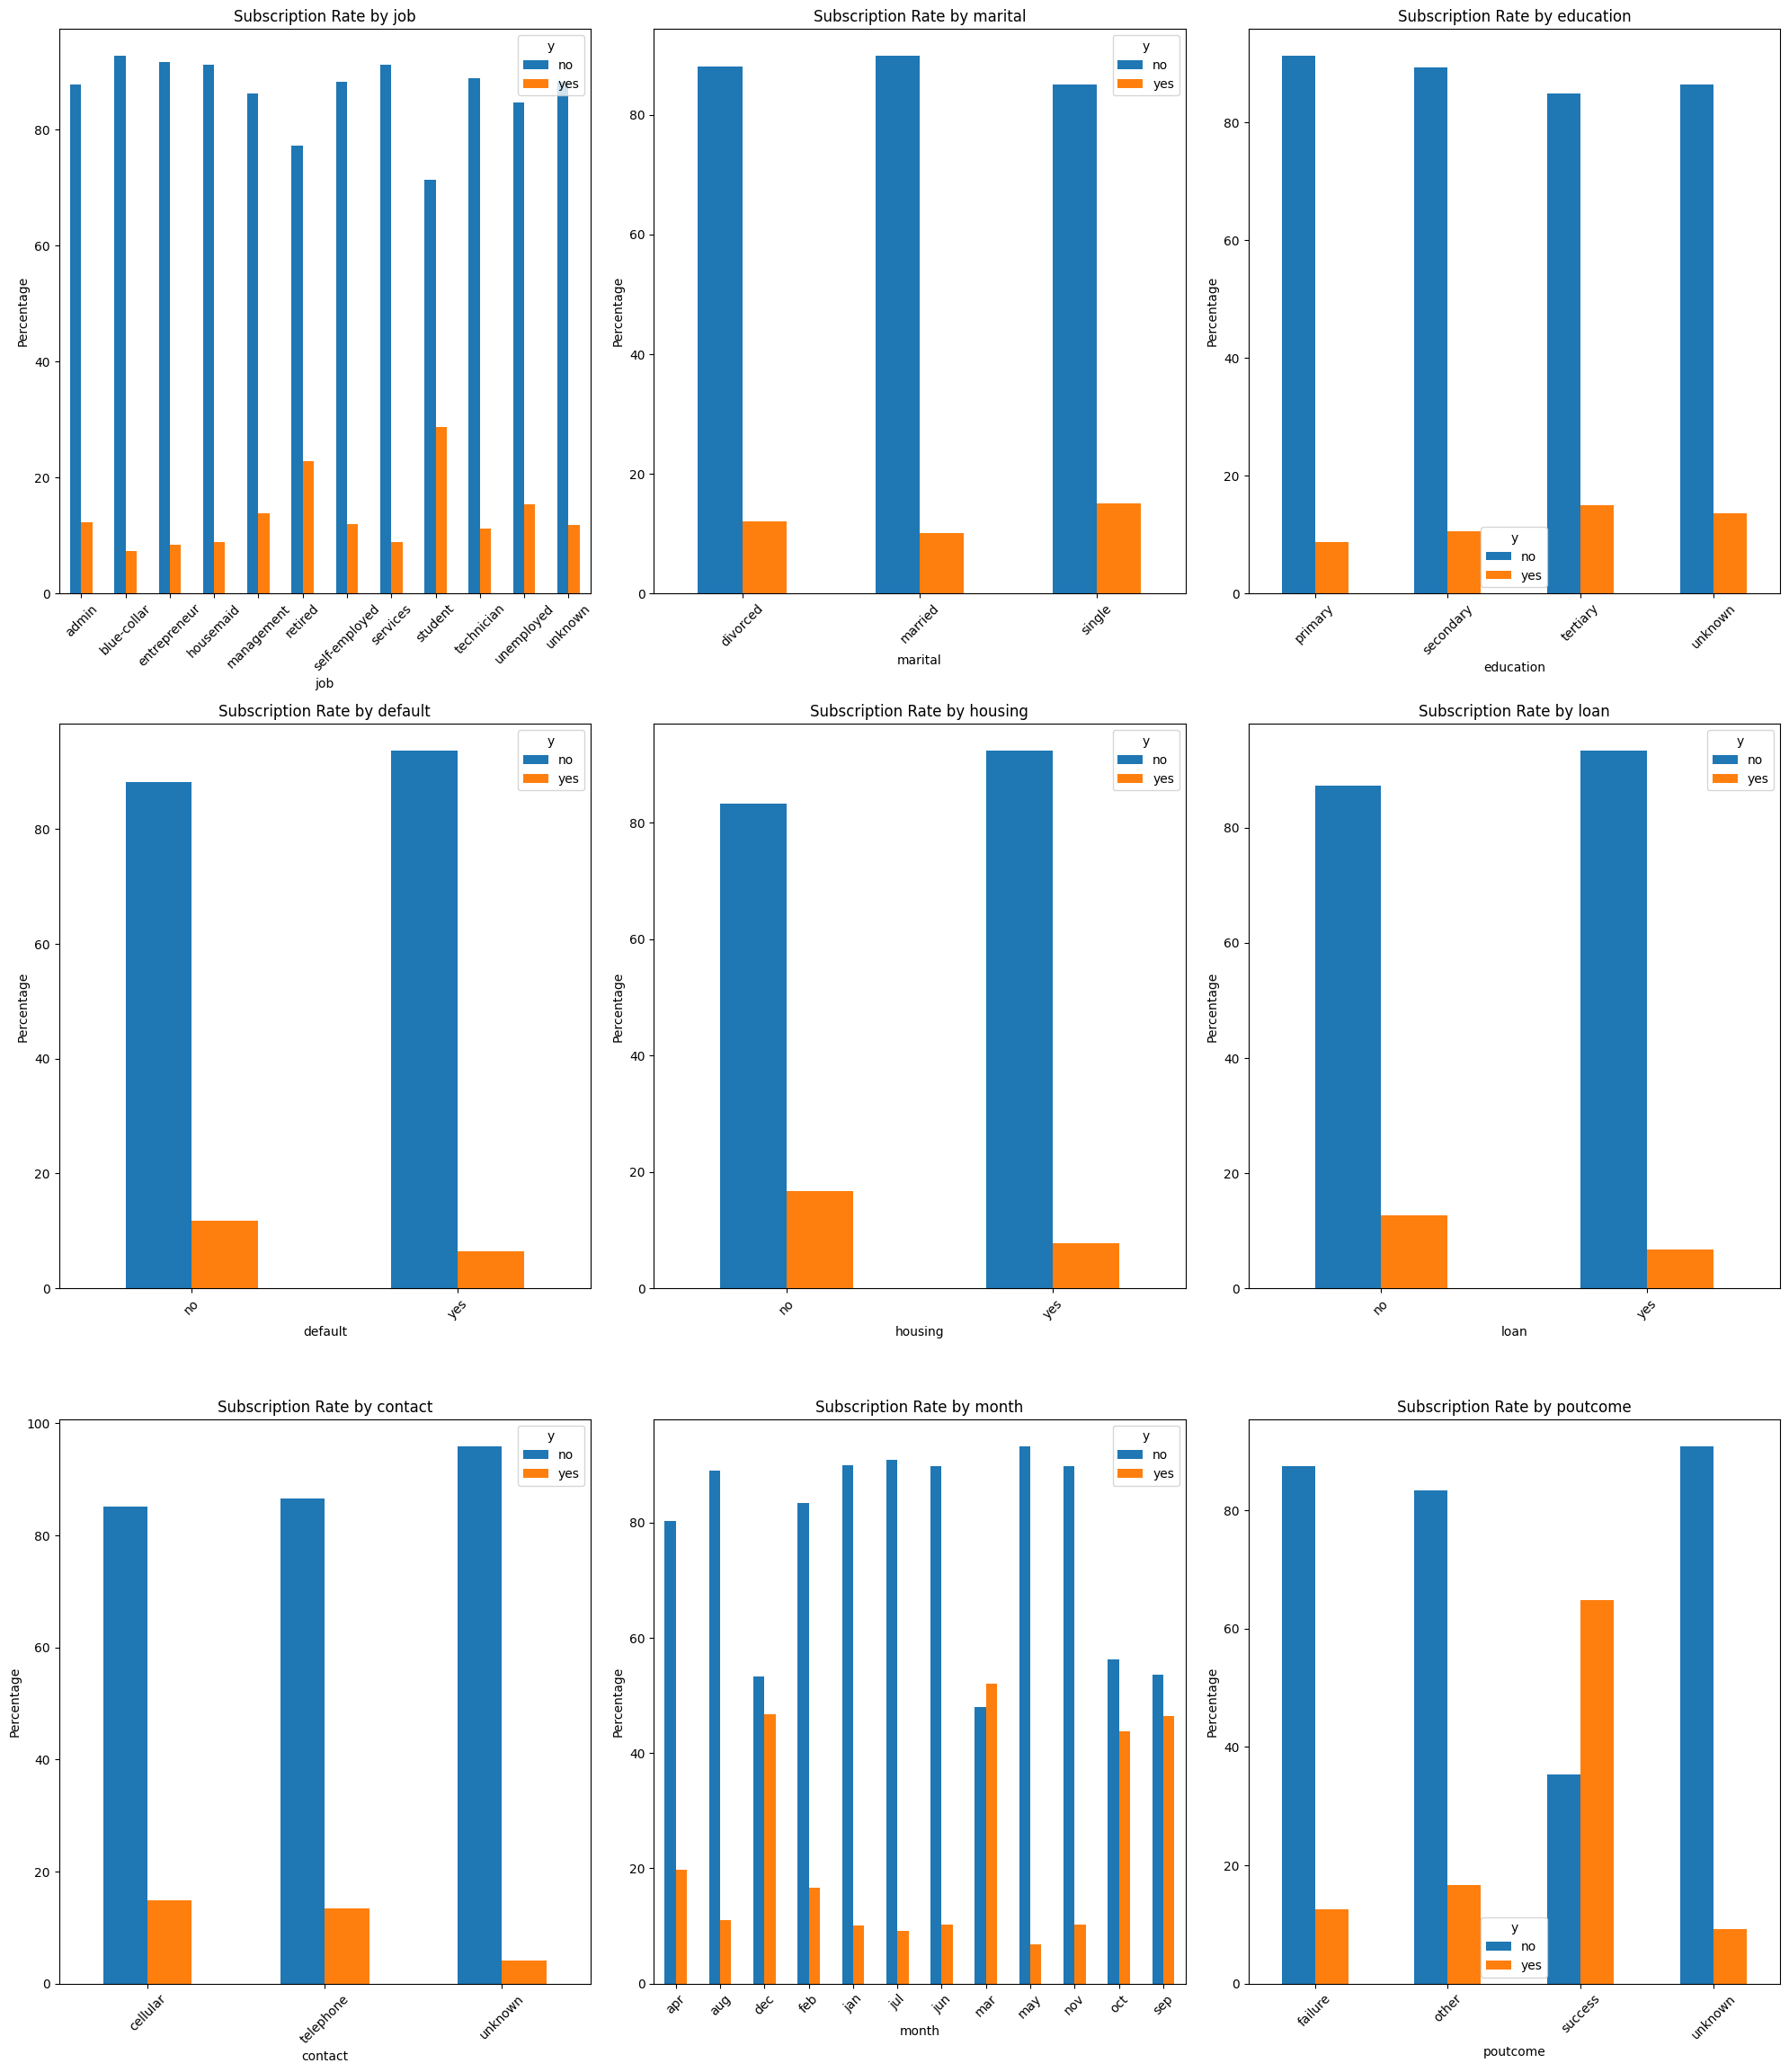

In [24]:
plt.figure(figsize=(20, 30), facecolor='white')

plotnumber = 1

for col in categorical_features:
    if col != 'y':
        rate = pd.crosstab(
            df[col], df['y'], normalize='index'
        ) * 100

        ax = plt.subplot(4, 3, plotnumber)
        rate.plot(kind='bar', ax=ax)

        plt.title(f'Subscription Rate by {col}')
        plt.ylabel('Percentage')
        plt.xticks(rotation=45)
        plotnumber += 1

plt.tight_layout()
plt.show()

Analyze numerical features against subscription

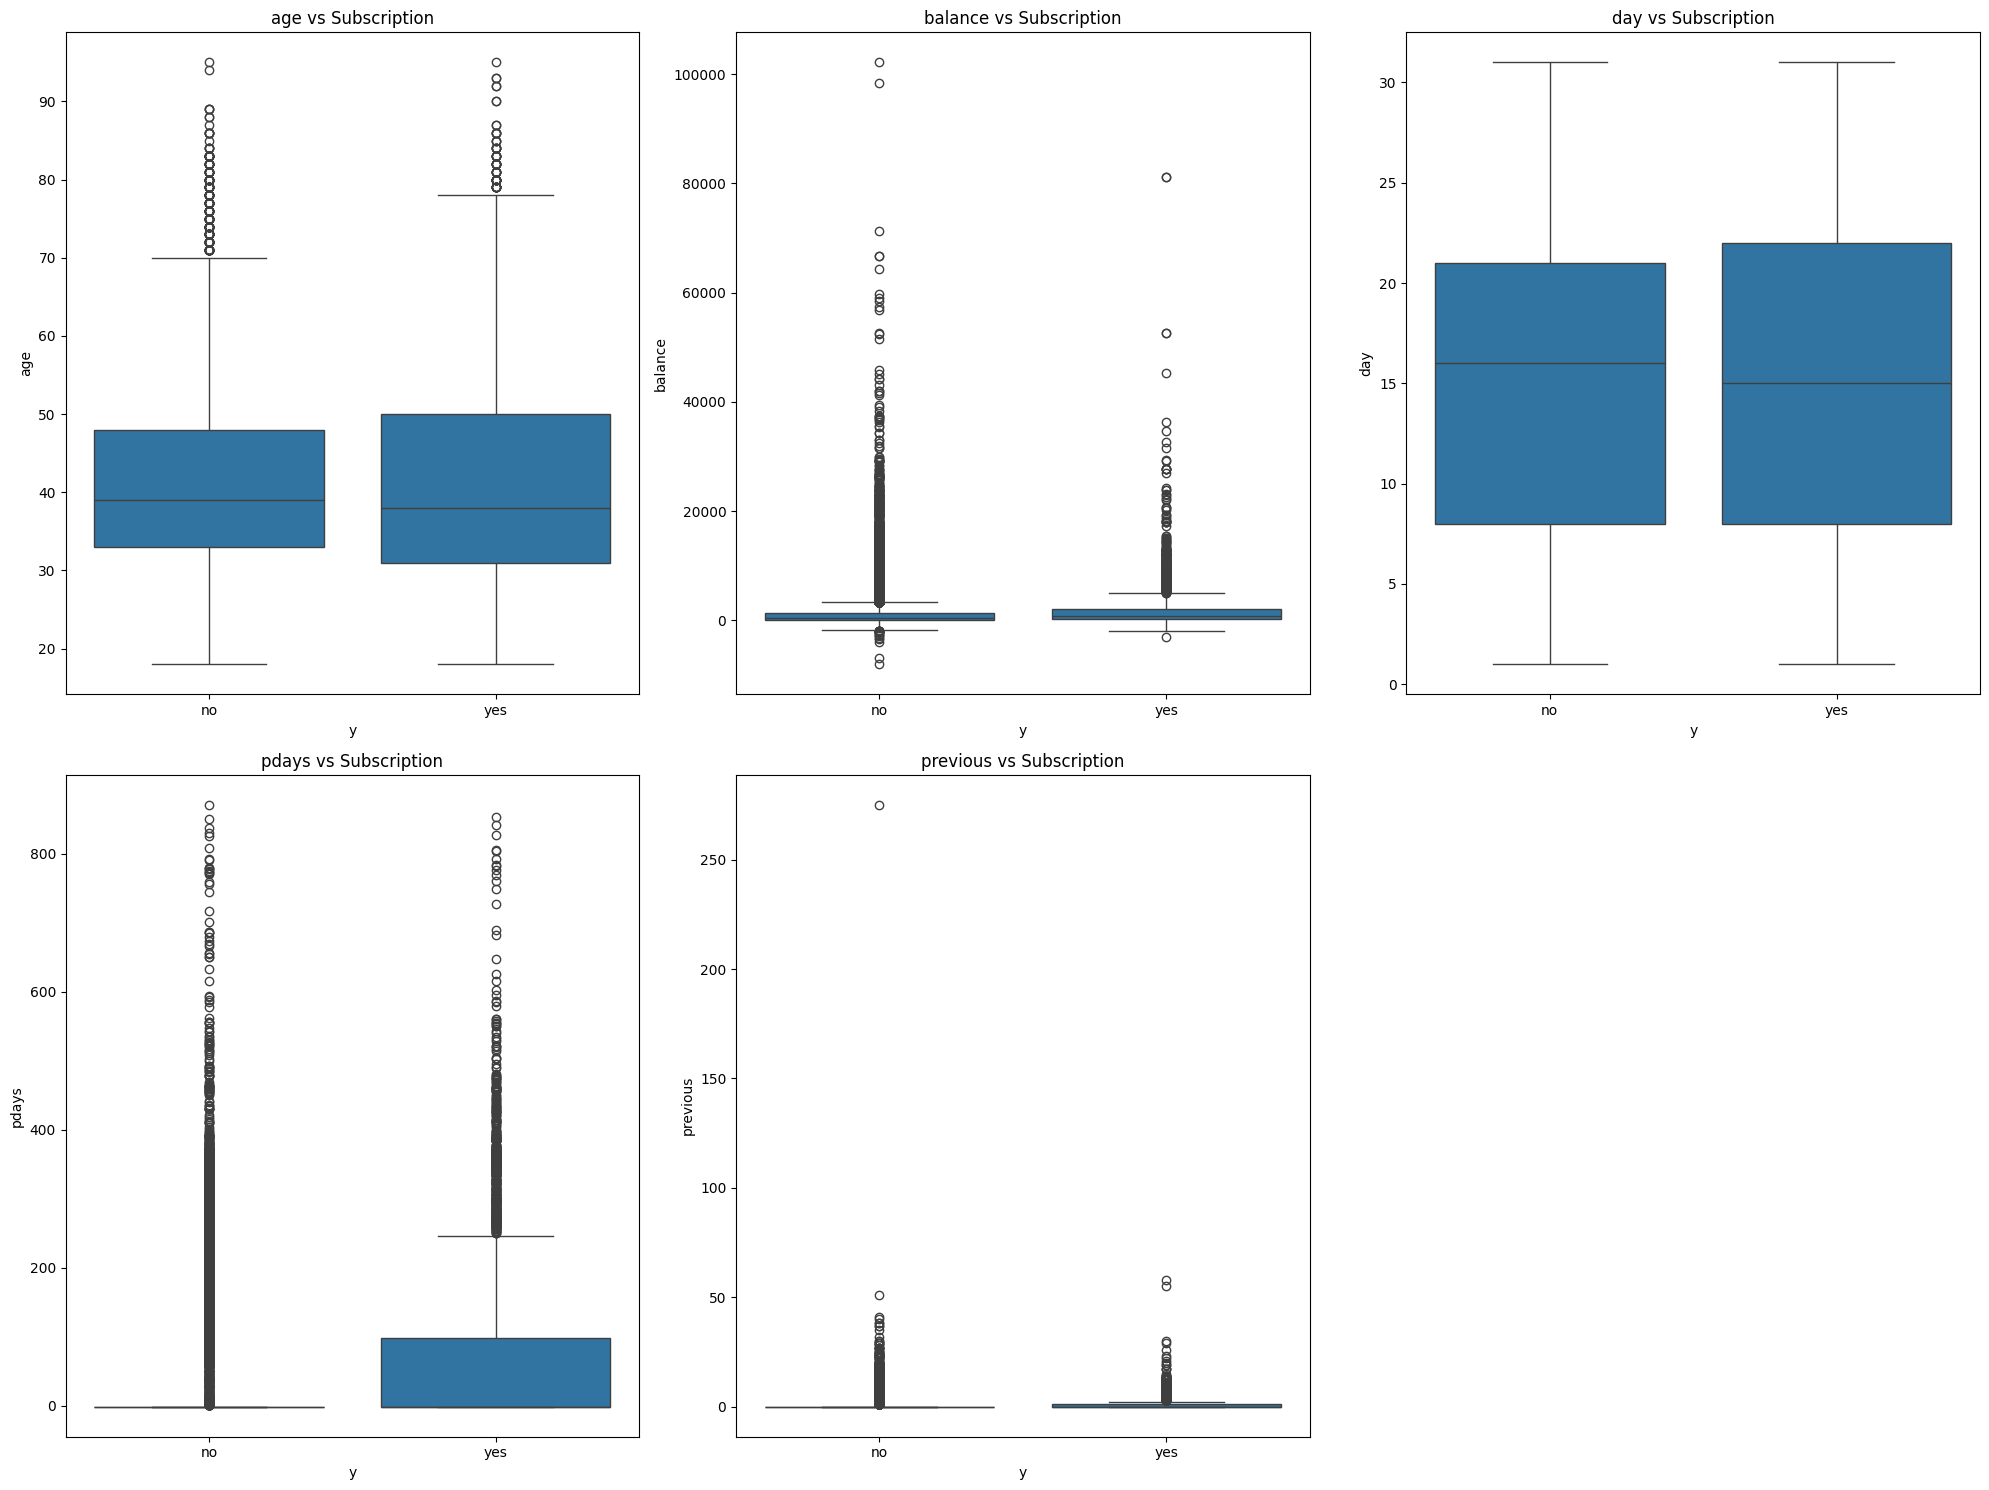

In [25]:
plt.figure(figsize=(20, 15), facecolor='white')

plotnumber = 1

for col in ["age", "balance", "day", "pdays", "previous"]:
    ax = plt.subplot(2, 3, plotnumber)
    sns.boxplot(data=df, x="y", y=col, ax=ax)
    plt.title(f"{col} vs Subscription")
    plotnumber += 1

plt.tight_layout()
plt.show()

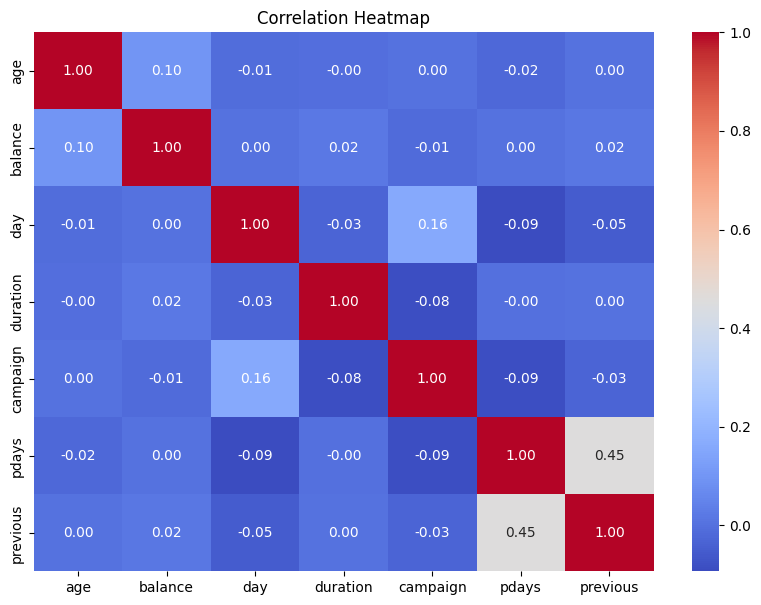

In [26]:
plt.figure(figsize=(10, 7))


sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

Feature selection and data leakage

In [27]:
df_model = df.drop(columns=['duration', 'campaign', 'day', 'month'])
df_model['y'] = df_model['y'].map({'no': 0, 'yes': 1})

X = df_model.drop(columns=['y'])
y = df_model['y']

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget counts:")
print(y.value_counts())

Features shape: (45211, 12)
Target shape: (45211,)

Target counts:
y
0    39922
1     5289
Name: count, dtype: int64


In [28]:
df_model

,age,job,marital,education,default,balance,housing,loan,contact,pdays,previous,poutcome,y
0,58.0,management,married,tertiary,no,2143,yes,no,unknown,-1,0,unknown,0
1,44.0,technician,single,secondary,no,29,yes,no,unknown,-1,0,unknown,0
2,33.0,entrepreneur,married,secondary,no,2,yes,yes,unknown,-1,0,unknown,0
3,47.0,blue-collar,married,unknown,no,1506,yes,no,unknown,-1,0,unknown,0
4,33.0,unknown,single,unknown,no,1,no,no,unknown,-1,0,unknown,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51.0,technician,married,tertiary,no,825,no,no,cellular,-1,0,unknown,1
45207,71.0,retired,divorced,primary,no,1729,no,no,cellular,-1,0,unknown,1
45208,72.0,retired,married,secondary,no,5715,no,no,cellular,184,3,success,1
45209,57.0,blue-collar,married,secondary,no,668,no,no,telephone,-1,0,unknown,0


In [29]:
df_model.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'pdays', 'previous', 'poutcome', 'y'],
      dtype='object')

In [30]:
X_train,X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape)
print(X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

(36168, 12)
(9043, 12)

Training target distribution:
y
0    0.883018
1    0.116982
Name: proportion, dtype: float64

Testing target distribution:
y
0    0.883003
1    0.116997
Name: proportion, dtype: float64


In [31]:
y_train.value_counts()

,count
y,
0,31937
1,4231


In [32]:
numerical_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(include="object").columns.tolist()

In [33]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer_ordinal = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
])

ordinal_preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numerical_features),
    ("cat", categorical_transformer_ordinal, categorical_features)
], verbose_feature_names_out=False
).set_output(transform="pandas")

categorical_indices = list(
    range(len(numerical_features),
    len(numerical_features) + len(categorical_features))
)


In [34]:
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),

    "Random Forest": RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42,
        class_weight='balanced'
    ),

    "XGBoost" : XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42,
    eval_metric='logloss'
)
}

In [35]:
results = []

for name, model in models.items():

    pipeline = Pipeline([
        ('preprocessor', ordinal_preprocessor),
        ('smotenc', SMOTENC(categorical_features=categorical_indices,random_state=42)),
        ('classifier', model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    print(name)
    print('-'*25)
    print(classification_report(y_test, y_pred, target_names=['No Subscription', 'Subscription']
),'\n')

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, pos_label=1),
        'Recall': recall_score(y_test, y_pred, pos_label=1),
        'F1 Score': f1_score(y_test, y_pred, pos_label=1),
        'ROC AUC': roc_auc_score(y_test, y_prob)
    })

Decision Tree
-------------------------
                 precision    recall  f1-score   support

No Subscription       0.91      0.85      0.88      7985
   Subscription       0.24      0.36      0.29      1058

       accuracy                           0.79      9043
      macro avg       0.57      0.61      0.58      9043
   weighted avg       0.83      0.79      0.81      9043
 

Random Forest
-------------------------
                 precision    recall  f1-score   support

No Subscription       0.92      0.88      0.90      7985
   Subscription       0.30      0.38      0.34      1058

       accuracy                           0.83      9043
      macro avg       0.61      0.63      0.62      9043
   weighted avg       0.84      0.83      0.83      9043
 

Gradient Boosting
-------------------------
                 precision    recall  f1-score   support

No Subscription       0.93      0.81      0.86      7985
   Subscription       0.27      0.55      0.37      1058

       ac

In [36]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='F1 Score',
    ascending=False
)

results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
2,Gradient Boosting,0.775849,0.273280,0.551985,0.365571,0.738870
4,XGBoost,0.771978,0.268450,0.550095,0.360818,0.737403
1,Random Forest,0.825058,0.303303,0.381853,0.338075,0.696965
3,Logistic Regression,0.641269,0.201366,0.696597,0.312421,0.713431
0,Decision Tree,0.790667,0.240199,0.364839,0.289681,0.605785


In [37]:
lr_param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__solver': ['liblinear', 'lbfgs'],
    'classifier__class_weight': ['balanced', None]
}

lr_pipeline = Pipeline([
    ('preprocessor', ordinal_preprocessor),
    ('smotenc', SMOTENC(
        categorical_features=categorical_indices,
        random_state=42
    )),
    ('classifier', LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

lr_grid_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

lr_grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['age',
                                                                          'balance',
                                                                          'pdays',
                                                                          'previous']),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('encoder',
                                                                                          OrdinalEncoder(handle_unknown='use_e...
                                                                          'poutcome'])],
                                                          verbose_feature_names_out=False)),
                                       ('smotenc',
                                        SMOTENC(categorical_features=[4, 5, 6,
                                                                      7, 8, 9,
                                                                      10, 11],
                                                random_state=42)),
                                       ('classifier',
                                        LogisticRegression(max_iter=2000,
                                                           random_state=42))]),
             n_jobs=-1,
             param_grid={'classifier__C': [0.01, 0.1, 1, 10, 100],
                         'classifier__class_weight': ['balanced', None],
                         'classifier__solver': ['liblinear', 'lbfgs']},
             scoring='f1', verbose=1)

In [38]:
print('classifier')
print("Best Parameters:", lr_grid_search.best_params_)
print("Best CV F1 Score:", lr_grid_search.best_score_)

lr_best_model = lr_grid_search.best_estimator_

y_pred = lr_best_model.predict(X_test)
y_prob = lr_best_model.predict_proba(X_test)[:, 1]

print(classification_report(
    y_test,
    y_pred,
    target_names=['No Subscription', 'Subscription']
))

print("ROC-AUC:", roc_auc_score(y_test, y_prob))

classifier
Best Parameters: {'classifier__C': 0.01, 'classifier__class_weight': 'balanced', 'classifier__solver': 'liblinear'}
Best CV F1 Score: 0.3057457676295057
                 precision    recall  f1-score   support

No Subscription       0.94      0.64      0.76      7985
   Subscription       0.20      0.69      0.31      1058

       accuracy                           0.64      9043
      macro avg       0.57      0.66      0.54      9043
   weighted avg       0.85      0.64      0.71      9043

ROC-AUC: 0.7160247889177842


In [39]:
gb_param_grid = {
    'classifier__n_estimators': [100, 150],
    'classifier__learning_rate': [0.05, 0.1],
    'classifier__max_depth': [2, 3]
}

gb_pipeline = Pipeline([
    ('preprocessor', ordinal_preprocessor),
    ('smotenc', SMOTENC(
        categorical_features=categorical_indices,
        random_state=42
    )),
    ('classifier', GradientBoostingClassifier(
        random_state=42
    ))
])

gb_grid_search = GridSearchCV(
    estimator=gb_pipeline,
    param_grid=gb_param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

gb_grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 8 candidates, totalling 40 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['age',
                                                                          'balance',
                                                                          'pdays',
                                                                          'previous']),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('encoder',
                                                                                          OrdinalEncoder(handle_unknown='use_e...
                                                                          'loan',
                                                                          'contact',
                                                                          'poutcome'])],
                                                          verbose_feature_names_out=False)),
                                       ('smotenc',
                                        SMOTENC(categorical_features=[4, 5, 6,
                                                                      7, 8, 9,
                                                                      10, 11],
                                                random_state=42)),
                                       ('classifier',
                                        GradientBoostingClassifier(random_state=42))]),
             n_jobs=-1,
             param_grid={'classifier__learning_rate': [0.05, 0.1],
                         'classifier__max_depth': [2, 3],
                         'classifier__n_estimators': [100, 150]},
             scoring='f1', verbose=1)

In [40]:
print("Best Parameters:", gb_grid_search.best_params_)
print("Best CV F1 Score:", gb_grid_search.best_score_)

gb_best_model = gb_grid_search.best_estimator_

y_pred = gb_best_model.predict(X_test)
y_prob = gb_best_model.predict_proba(X_test)[:, 1]

print(classification_report(
    y_test,
    y_pred,
    target_names=['No Subscription', 'Subscription']
))

print("ROC-AUC:", roc_auc_score(y_test, y_prob))

Best Parameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__n_estimators': 150}
Best CV F1 Score: 0.37944693835849475
                 precision    recall  f1-score   support

No Subscription       0.92      0.86      0.89      7985
   Subscription       0.31      0.47      0.37      1058

       accuracy                           0.82      9043
      macro avg       0.62      0.66      0.63      9043
   weighted avg       0.85      0.82      0.83      9043

ROC-AUC: 0.7339185121441076


In [41]:
lr_final_model = lr_best_model
gb_final_model = gb_best_model

In [42]:
lr_pred = lr_final_model.predict(X_test)
gb_pred = gb_final_model.predict(X_test)

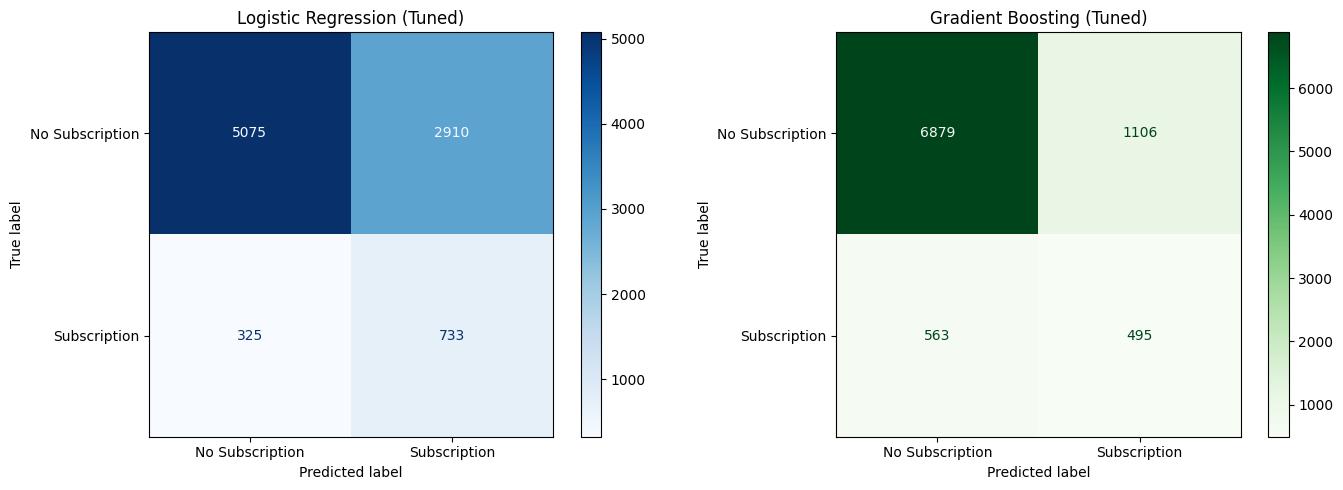

In [43]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Logistic Regression
ConfusionMatrixDisplay.from_predictions(
    y_test,
    lr_pred,
    display_labels=['No Subscription', 'Subscription'],
    cmap='Blues',
    values_format='d',
    ax=ax[0]
)

ax[0].set_title('Logistic Regression (Tuned)')

# Gradient Boosting
ConfusionMatrixDisplay.from_predictions(
    y_test,
    gb_pred,
    display_labels=['No Subscription', 'Subscription'],
    cmap='Greens',
    values_format='d',
    ax=ax[1]
)

ax[1].set_title('Gradient Boosting (Tuned)')

plt.tight_layout()
plt.show()

In [44]:
final_model = gb_final_model

In [45]:
y_new = [[72.0	,'retired',	'married'	,'secondary',	'no'	,5715	,'no'	,'no', 'cellular',	184	,3,	'success'	]]

new_customer = pd.DataFrame(y_new, columns=X_train.columns)

In [46]:
prediction = final_model.predict(new_customer)

print("Prediction:", prediction)

Prediction: [1]


In [47]:
if prediction[0] == 1:
    print("Customer will subscribe.")
else:
    print("Customer will not subscribe.")

Customer will subscribe.


In [48]:
probability = final_model.predict_proba(new_customer)

print("No Subscription:", probability[0][0] * 100)
print("Subscription:", probability[0][1] * 100)

No Subscription: 5.299910672431674
Subscription: 94.70008932756832


In [49]:
with open('bank_term_deposit_model.pkl', 'wb') as file:
    pickle.dump(final_model, file)

In [50]:
import imblearn
print(imblearn.__version__)

0.14.2
